In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install wfdb

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 83.7 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.2
    Uninstalling pandas-2.2.2:
      Successfully uninstalled pandas-2.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.3 which is incompatible.
dask-cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.3 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.3 which is incompatible.


In [ ]:
import os
import warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# !pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

import wfdb
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay
)

from tqdm import tqdm

warnings.filterwarnings('ignore')


SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')

Using device: cuda


In [ ]:
import os

DATA_DIR = '/content/drive/MyDrive/apnea_ecg_data'

DB_NAME = 'apnea-ecg'

os.makedirs(DATA_DIR, exist_ok=True)

print("Folder ready:", DATA_DIR)

Folder ready: /content/drive/MyDrive/apnea_ecg_data


In [ ]:
RECORD_NAMES = (
    [f'a{i:02d}' for i in range(1, 21)] +   # a01 .. a20  (apnea patients)
    [f'b{i:02d}' for i in range(1, 6)]  +   # b01 .. b05  (borderline)
    [f'c{i:02d}' for i in range(1, 11)]     # c01 .. c10  (control/normal)
)

In [ ]:
# ------------------FIRST TIME-----------

# import wfdb

# DB_NAME = 'apnea-ecg'

# wfdb.dl_database(
#     db_dir     = DB_NAME,
#     dl_dir     = DATA_DIR,
#     records    = RECORD_NAMES,
#     annotators = ['apn']
# )

# print(f"\nDone->{len(RECORD_NAMES)}records saved.")

In [ ]:
# -------NEXT-TIME USE-----
  # NO-redownloading required

import wfdb
record = wfdb.rdrecord(f'{DATA_DIR}/a01')
print("Loaded from Drive ", record.p_signal.shape)

Loaded from Drive  (2957000, 1)


In [ ]:
FS= 100
EPOCH_SEC= 40
STEP_SEC= 15
EPOCH_SAMPLES=FS * EPOCH_SEC
STEP_SAMPLES  = FS * STEP_SEC
PRIOR_COUNT   = 3

print(f'Epoch length : {EPOCH_SEC} s->{EPOCH_SAMPLES} samples')
print(f'Sliding step : {STEP_SEC} s  → {STEP_SAMPLES} samples')
print(f'Prior window : {PRIOR_COUNT} epochs before an apnea event')

Epoch length : 40 s->4000 samples
Sliding step : 15 s  → 1500 samples
Prior window : 3 epochs before an apnea event


In [ ]:
def load_record(record_name, data_dir):
    """
    Returns:
        signal (np.ndarray): 1-D ECG signal, shape (N,)
        ann_samples (list): sample indices of each annotation
        ann_labels  (list): 'A' or 'N' for each annotation
    """

    record_path = os.path.join(data_dir, record_name)

    # Read the raw ECG signal
    record = wfdb.rdrecord(record_path)
    signal = record.p_signal[:, 0].astype(np.float32)

    ann = wfdb.rdann(record_path, extension='apn')

    return signal, ann.sample, ann.symbol


def normalize_signal(signal):
     mean = np.mean(signal)
     std  = np.std(signal)+ 1e-8
     return (signal - mean) / std


def segment_and_label(signal, ann_samples, ann_labels,
                      epoch_samples, step_samples, prior_count):

    ann_samples = np.array(ann_samples)
    ann_labels  = np.array(ann_labels)
    is_apnea    = ann_labels == 'A'

    n_samples = len(signal)
    epochs, raw_labels = [], []

    # Step A: sliding window ─
    start = 0
    while start + epoch_samples <= n_samples:
        end  = start + epoch_samples
        mask = (ann_samples >= start) & (ann_samples < end) & is_apnea
        raw_labels.append('apnea' if mask.any() else 'normal')
        epochs.append(normalize_signal(signal[start:end]))
        start += step_samples

    # Step B: improved prior labeling
    raw_labels   = np.array(raw_labels)
    final_labels = raw_labels.copy()

    # Find only cluster starts — first apnea in each consecutive group
    apnea_starts = [
        i for i, lbl in enumerate(raw_labels)
        if lbl == 'apnea' and (i == 0 or raw_labels[i-1] != 'apnea')
    ]

    for i in apnea_starts:
        # Dynamic prior count based on apnea cluster size
        cluster_size = 0
        k = i
        while k < len(raw_labels) and raw_labels[k] == 'apnea':
            cluster_size += 1
            k += 1
        dynamic_prior = min(cluster_size + 2, prior_count + 2)

        # Walk backwards — don't stop at apnea, skip it
        count = 0
        j = i - 1
        while j >= 0 and count < dynamic_prior:
            if raw_labels[j] == 'normal':
                final_labels[j] = 'prior'
                count += 1
            j -= 1   # ← key change: no break, skip apneas

    return epochs, final_labels.tolist()


def segment_and_label(signal, ann_samples, ann_labels,
                      epoch_samples, step_samples, prior_count):

    ann_samples = np.array(ann_samples)
    ann_labels  = np.array(ann_labels)
    is_apnea    = ann_labels == 'A'

    n_samples = len(signal)
    epochs, raw_labels = [], []

    # ── Step A: sliding window ─────────────────────────────────────────────────
    start = 0
    while start + epoch_samples <= n_samples:
        end  = start + epoch_samples
        mask = (ann_samples >= start) & (ann_samples < end) & is_apnea
        raw_labels.append('apnea' if mask.any() else 'normal')
        epochs.append(normalize_signal(signal[start:end]))
        start += step_samples

    # ── Step B: improved prior labeling
    raw_labels   = np.array(raw_labels)
    final_labels = raw_labels.copy()

    # Find only cluster starts — first apnea in each consecutive group
    apnea_starts = [
        i for i, lbl in enumerate(raw_labels)
        if lbl == 'apnea' and (i == 0 or raw_labels[i-1] != 'apnea')
    ]

    for i in apnea_starts:
        # Dynamic prior count based on apnea cluster size
        cluster_size = 0
        k = i
        while k < len(raw_labels) and raw_labels[k] == 'apnea':
            cluster_size += 1
            k += 1
        dynamic_prior = min(cluster_size + 2, prior_count + 2)

        # Walk backwards — don't stop at apnea, skip it
        count = 0
        j = i - 1
        while j >= 0 and count < dynamic_prior:
            if raw_labels[j] == 'normal':
                final_labels[j] = 'prior'
                count += 1
            j -= 1   # ← key change: no break, skip apneas

    return epochs, final_labels.tolist()



# def segment_and_label(signal, ann_samples, ann_labels,
#                        epoch_samples, step_samples, prior_count):

#     n_samples = len(signal)
#     epochs, raw_labels = [], []

#     # Step A:slide window across the full signal
#     start = 0
#     while start + epoch_samples <= n_samples:
#         end   = start + epoch_samples
#         epoch = signal[start:end]

#         # Checking if any apnea annotation falls inside this epoch
#         has_apnea = any(
#             ann_samples[i] >= start and ann_samples[i] < end and ann_labels[i] == 'A'
#             for i in range(len(ann_samples))
#         )
#         raw_labels.append('apnea' if has_apnea else 'normal')
#         epochs.append(normalize_signal(epoch))
#         start += step_samples

#     # mark 'prior' epochs:
#     # The [prior_count] consecutive normal epochs just before any apnea epoch
#     final_labels = raw_labels.copy()
#     for i, lbl in enumerate(raw_labels):
#         if lbl == 'apnea':
#             # Walk backwards to find up to prior_count normal epochs
#             count = 0
#             j = i - 1
#             while j >= 0 and count<prior_count:
#                 if raw_labels[j] == 'normal':
#                     final_labels[j] = 'prior'
#                     count += 1
#                 else:
#                     break   #stop if another apnea  encountered
#                 j -= 1

#     return epochs, final_labels

In [ ]:
#  Processing  all records
all_epochs  = []   # list of np.ndarray (each: EPOCH_SAMPLES,)
all_labels  = []   # list of str: 'normal', 'prior', 'apnea'

for rec in tqdm(RECORD_NAMES, desc='Processing records'):
    try:
        signal, ann_samples, ann_labels = load_record(rec, DATA_DIR)
        epochs, labels = segment_and_label( signal, ann_samples, ann_labels,EPOCH_SAMPLES, STEP_SAMPLES, PRIOR_COUNT)
        all_epochs.extend(epochs)
        all_labels.extend(labels)
    except Exception as e:
        print(f'[skip] {rec}: {e}')

# Convert to numpy arrays for easier manipulation
all_epochs = np.array(all_epochs, dtype=np.float32)  # (N, EPOCH_SAMPLES)
all_labels = np.array(all_labels)

# Print epoch counts per class
unique, counts = np.unique(all_labels, return_counts=True)
print('\nEpoch distribution (before balancing):')
for u, c in zip(unique, counts):
    print(f'  {u:8s}: {c:,}')

Processing records: 100%|██████████| 35/35 [00:58<00:00,  1.68s/it]



Epoch distribution (before balancing):
  apnea   : 19,537
  normal  : 40,948
  prior   : 7,766


In [ ]:
#  Prior vs Normal :
# We 'EXCLUDE' actual apnea epochs from classification
# We 'BALANCE' classes by randomly undersampling 'normal' to match 'prior' count.


# ------------------------------------------------------
# Your dataset:
#   prior  =   800  (what you want to detect)
#   normal =  11800  (14x more)

# Class weights tells model:
#   "missing a prior is 14x worse than missing a normal"
#   → model tries much harder to catch prior epochs
#   → sensitivity goes UP
#   → no data wasted
#   → no fake data added
#   → one line change


# pos_weight = 5.27  means:
#   normal is 5.27x more common than prior

# With class weights:
#  ==> missing a prior  →  penalized 5.27x more
#  ==> missing a normal →  penalized 1x

# Model automatically compensates :
# ==> No need to throw away 40,000 normal samples

# --------------------------------------------------------






# prior_idx  = np.where(all_labels == 'prior')[0]
# normal_idx = np.where(all_labels == 'normal')[0]

# print(f'Prior epochs  : {len(prior_idx):,}')
# print(f'Normal epochs : {len(normal_idx):,}  (will be undersampled)')

# rng = np.random.default_rng(SEED)
# sampled_normal_idx = rng.choice(normal_idx, size=len(prior_idx), replace=False)

# # Combine and shuffle
# selected_idx = np.concatenate([prior_idx, sampled_normal_idx])
# rng.shuffle(selected_idx)

# X = all_epochs[selected_idx]
# y = (all_labels[selected_idx] == 'prior').astype(int) # 1 = prior,0=normal

# print(f'\nFinal balanced dataset:')
# print(f'  X shape : {X.shape}')
# print(f'  Prior (1): {y.sum():,}  |  Normal (0): {(1-y).sum():,}')

prior_idx  = np.where(all_labels == 'prior')[0]
normal_idx = np.where(all_labels == 'normal')[0]

# Keep ALL data
selected_idx = np.concatenate([prior_idx, normal_idx])
rng = np.random.default_rng(SEED)
rng.shuffle(selected_idx)

X = all_epochs[selected_idx]
y = (all_labels[selected_idx] == 'prior').astype(int)

# Compute pos_weight for loss
n_normal = len(normal_idx)
n_prior  = len(prior_idx)
pos_weight = torch.tensor(n_normal / n_prior).to(DEVICE)

print(f'pos_weight: {pos_weight:.2f}')   # ~14.75
print(f'X shape: {X.shape}')
print(f'Prior: {y.sum()} | Normal: {(1-y).sum()}')

# Then in fold loop change criterion to:
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

pos_weight: 5.27
X shape: (48714, 4000)
Prior: 7766 | Normal: 40948


In [ ]:
print(EPOCH_SAMPLES)   # should match X.shape[1] = 4000

4000


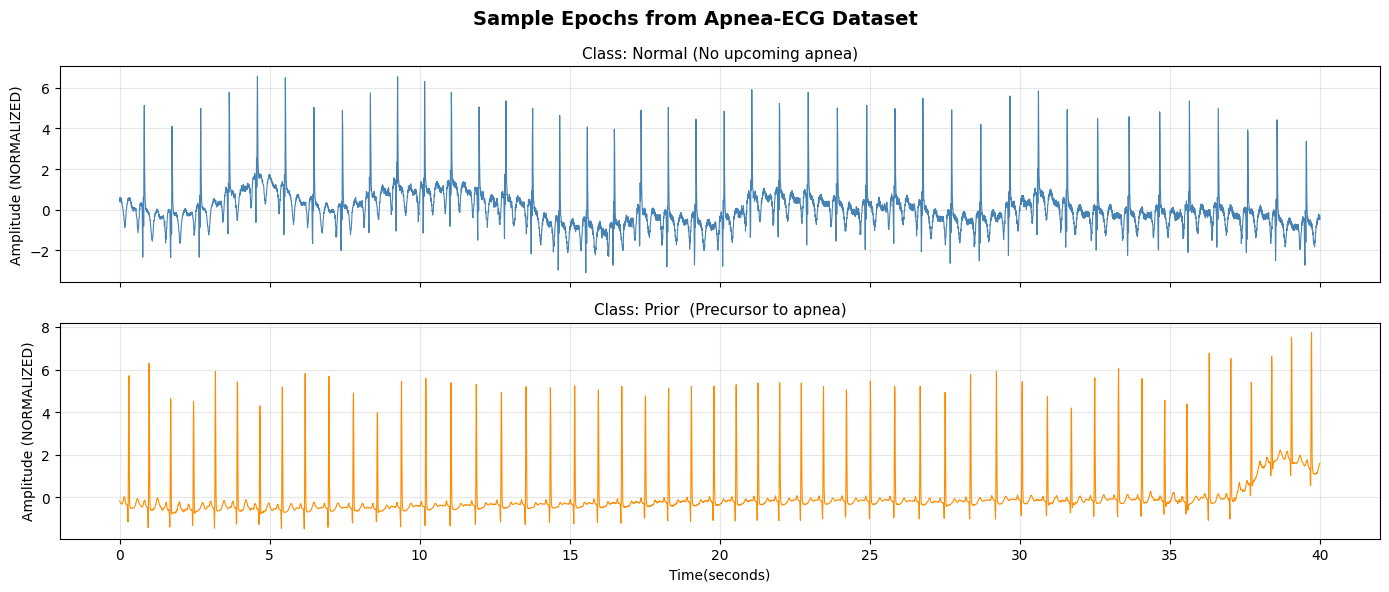

In [ ]:
# Plot :


time_axis = np.linspace(0, EPOCH_SEC, EPOCH_SAMPLES)  # x-axis in seconds

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
fig.suptitle('Sample Epochs from Apnea-ECG Dataset', fontsize=14, fontweight='bold')

for ax, label_val, label_name, color in [
    (axes[0], 0,'Normal (No upcoming apnea)', 'steelblue'),
    (axes[1], 1, 'Prior  (Precursor to apnea)', 'darkorange')
]:

    # Pick first epoch of this class
    idx = np.where(y==label_val)[0][0]
    ax.plot(time_axis, X[idx], color=color, linewidth=0.8)
    ax.set_ylabel('Amplitude (NORMALIZED)')
    ax.set_title(f'Class: {label_name}', fontsize=11)
    ax.grid(True, alpha=0.3)

axes[1].set_xlabel('Time(seconds)')
plt.tight_layout()
plt.savefig('sample_epochs.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
class ApneaEpochDataset(Dataset):

    def __init__(self, X, y):
        # Adding  channel dimension: (N, 1, T)
        self.X = torch.tensor(X[:, np.newaxis, :], dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


test_ds = ApneaEpochDataset(X, y)
sample_x, sample_y = test_ds[0]
print(f'Single sample-X: {sample_x.shape}, y: {sample_y}')

Single sample-X: torch.Size([1, 4000]), y: 0.0


In [ ]:
class ConvBlock(nn.Module):
    """
    One convolutional block = Conv1D → BatchNorm → ReLU
    """
    def __init__(self, in_channels, out_channels, kernel_size, padding):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv1d(in_channels, out_channels,
                      kernel_size=kernel_size, stride=1, padding=padding),
            nn.BatchNorm1d(out_channels),
            nn.ReLU()
        )

    def forward(self, x):
        return self.block(x)


In [ ]:
class CNNTransformerModel(nn.Module):
    """
    CNN-Transformer for sleep apnea event prediction.

    Input : (batch, 1, T)  where T = EPOCH_SAMPLES
    Output: (batch, 1)     probability of 'prior' class (0–1)

    """
    def __init__(self,
                 in_channels   = 1,
                 d_model       = 64,    # transformer input/output dim
                 nhead         = 8,     # attention heads
                 num_layers    = 2,     # stacked transformer encoders
                 dim_feedfwd   = 128,   # FFN hidden dim
                 dropout_tf    = 0.3,   # transformer dropout
                 dropout_cls   = 0.5,   # classifier dropout
                ):
        super().__init__()

        # Feature Extraction: 3 CNN blocks:

        # Block 1: smaller kernel (local features, smaller receptive field)
        self.cnn1 = ConvBlock(in_channels, 32, kernel_size=3,  padding=1)

        # Block 2: larger kernel (global features, larger receptive field)
        self.cnn2 = ConvBlock(32,32, kernel_size=29, padding=14)

        # Block 3: expand channels to d_model=64
        self.cnn3 = ConvBlock(32, 64, kernel_size=29, padding=14)

        # Output of CNN: (batch, 64, T)same temporal length due to padding


        self.pool  = nn.MaxPool1d(kernel_size=10)

        # Transformer Encoder (sequence modeling):

        encoder_layer = nn.TransformerEncoderLayer(
            d_model        = d_model,
            nhead          = nhead,
            dim_feedforward= dim_feedfwd,
            dropout        = dropout_tf,
            activation     = 'relu',
            batch_first    = True
        )

        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # Prediction Head :

        # Average pool over seq_len dimension, then classify
        self.dropout   = nn.Dropout(dropout_cls)
        self.linear    = nn.Linear(d_model, 1)
        self.sigmoid   = nn.Sigmoid()

    def forward(self, x):
        # x: (batch, 1, T)

        #CNN feature extraction

        x = self.cnn1(x)   #(batch, 32, T)
        x = self.cnn2(x)   #(batch, 32, T)
        x = self.cnn3(x)   #(batch, 64, T)

        x = self.pool(x)

        # Transpose for Transformer: (batch, 64, T)->(batch, T, 64)
        x = x.permute(0, 2, 1)

        #Transformer encoding---> to capture long-range dependencies
        x = self.transformer(x)   # (batch, T, 64)

        #Average pooling over time dimension
        x = x.mean(dim=1)         # (batch, 64)

        #Classifier
        x = self.dropout(x)        # regularization
        x = self.linear(x)         # (batch, 1)

        return x.squeeze(1)        # (batch,)


model_test = CNNTransformerModel().to(DEVICE)
dummy_in   = torch.zeros(4, 1, EPOCH_SAMPLES).to(DEVICE)
dummy_out  = model_test(dummy_in)
print(f'Model output shape for batch=4 : {dummy_out.shape} (expected: torch.Size([4]))')

total_params = sum(p.numel() for p in model_test.parameters() if p.requires_grad)
print(f'Total trainable parameters : {total_params:,}')

Model output shape for batch=4 : torch.Size([4]) (expected: torch.Size([4]))
Total trainable parameters : 156,577


In [ ]:
from torch.cuda.amp import autocast, GradScaler

scaler = GradScaler()

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    """
    Run one full training epoch.
    Returns: average loss over all batches
    """

    model.train()
    total_loss = 0.0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        with autocast():
            preds = model(X_batch)
            loss  = criterion(preds, y_batch)

        scaler.scale(loss).backward() # scaled backward
        scaler.step(optimizer)  # update weights
        scaler.update()   # update scaler

        total_loss += loss.item()

    return total_loss / len(loader)


@torch.no_grad()
def evaluate(model, loader, criterion, device, threshold=0.5):
    """
    Evaluating model on a DataLoader:
    Returns:
        loss        : average BCE loss
        accuracy    : (TP+TN) / total
        sensitivity : TP / (TP+FN) --recall for 'prior' class
        f1          : F1 score for 'prior' class
        y_true, y_pred: arrays for confusion matrix plotting
    """
    model.eval()
    total_loss = 0.0
    y_true_all, y_pred_all = [], []

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        probs = model(X_batch)
        loss  = criterion(probs, y_batch)
        total_loss += loss.item()

        preds = (torch.sigmoid(probs) >= threshold).long().cpu().numpy()
        y_true_all.extend(y_batch.cpu().numpy().astype(int))
        y_pred_all.extend(preds)

    y_true = np.array(y_true_all)
    y_pred = np.array(y_pred_all)

    acc  = accuracy_score(y_true, y_pred)
    sens = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    f1   = f1_score(y_true, y_pred, pos_label=1, zero_division=0)

    return total_loss / len(loader), acc, sens, f1, y_true, y_pred

In [ ]:
# Hyperparameters
BATCH_SIZE  = 16
EPOCHS  = 15
LR  = 1e-3
N_FOLDS = 5


# storing results:
fold_results = []  # each entry:dict with acc, sens, f1
all_y_true   = []  # collected across all test folds
all_y_pred   = []

# History for plotting training curves
train_loss_history = []
val_loss_history   = []

# Stratified K-Fold: preserves class distribution in each fold
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

full_dataset = ApneaEpochDataset(X, y)

print(f'Starting {N_FOLDS}-Fold Cross-Validation')
print(f'Epochs per fold: {EPOCHS} | Batch size: {BATCH_SIZE} | LR: {LR}\n')


Starting 5-Fold Cross-Validation
Epochs per fold: 15 | Batch size: 16 | LR: 0.001



In [ ]:
best_overall_f1    = 0
best_overall_state = None
best_overall_fold  = 0

In [ ]:
for fold, (trainval_idx, test_idx) in enumerate(skf.split(np.zeros(len(y)), y), start=1):

    print(f'\n FOLD {fold}/{N_FOLDS}')
    print('  ' + '-' * 55)


    # train (87.5%) + val (12.5%)
    n_val= max(1, int(0.125 * len(trainval_idx)))

    rng.shuffle(trainval_idx)


    val_idx  = trainval_idx[:n_val]
    train_idx= trainval_idx[n_val:]

    #DataLoaders
    train_loader = DataLoader(
        Subset(full_dataset, train_idx),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=2,pin_memory=True
    )
    val_loader = DataLoader(
        Subset(full_dataset, val_idx),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=2,pin_memory=True
    )
    test_loader = DataLoader(
        Subset(full_dataset, test_idx),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=2,pin_memory=True
    )



    print(f'Train: {len(train_idx):,}  |  Val: {len(val_idx):,}  |  Test: {len(test_idx):,}')



    # Fresh model for each fold :
    model     = CNNTransformerModel().to(DEVICE)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)     # binary cross-entropy
    optimizer = optim.Adam(model.parameters(), lr=LR)  # Adam optimizer

    best_val_loss  = float('inf')
    best_state  = None
    fold_tr_losses = []
    fold_vl_losses = []
    patience       = 5
    no_improve     = 0


    #Training:
    for epoch in range(1, EPOCHS + 1):
        tr_loss = train_one_epoch(model, train_loader, optimizer, criterion, DEVICE)
        vl_loss, vl_acc, vl_sens, vl_f1, _, _ = evaluate(model, val_loader,criterion, DEVICE)

        fold_tr_losses.append(tr_loss)
        fold_vl_losses.append(vl_loss)

        # Save best model weights based on validation loss
        if vl_loss < best_val_loss:
            best_val_loss = vl_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f'  Early stop at epoch {epoch}')
                break


        if epoch % 5 == 0 or epoch == 1:
            print(f'  Epoch {epoch:3d}/{EPOCHS} — ' f'Train Loss: {tr_loss:.4f} | '  f'Val Loss: {vl_loss:.4f} | ' f'Val Acc: {vl_acc:.3f}')

    # Test evaluation with best weights:
    model.load_state_dict(best_state)   # restoring best checkpoint
    _, te_acc, te_sens, te_f1, yt, yp = evaluate(
        model, test_loader, criterion, DEVICE
    )

    fold_results.append({'fold': fold, 'accuracy': te_acc,'sensitivity': te_sens, 'f1': te_f1})


    all_y_true.extend(yt)
    all_y_pred.extend(yp)


    train_loss_history.append(fold_tr_losses)
    val_loss_history.append(fold_vl_losses)


    print(f'Fold {fold} Test -->'f'Acc: {te_acc:.4f} | Sens: {te_sens:.4f}| F1: {te_f1:.4f}')

    if te_f1 > best_overall_f1:
        best_overall_f1    = te_f1
        best_overall_state = best_state.copy()
        best_overall_fold  = fold

    del model, optimizer, best_state
    torch.cuda.empty_cache()


print('\n'+'=' * 65)
print('Cross-Validation Complete!')


 FOLD 1/5
  -------------------------------------------------------
Train: 34,100  |  Val: 4,871  |  Test: 9,743
  Epoch   1/15 — Train Loss: 0.7779 | Val Loss: 0.6373 | Val Acc: 0.823
  Epoch   5/15 — Train Loss: 0.5238 | Val Loss: 0.5087 | Val Acc: 0.879
  Epoch  10/15 — Train Loss: 0.4682 | Val Loss: 0.6322 | Val Acc: 0.927
  Epoch  15/15 — Train Loss: 0.4178 | Val Loss: 0.4879 | Val Acc: 0.912
Fold 1 Test -->Acc: 0.8946 | Sens: 0.8519| F1: 0.7204

 FOLD 2/5
  -------------------------------------------------------
Train: 34,100  |  Val: 4,871  |  Test: 9,743
  Epoch   1/15 — Train Loss: 0.7728 | Val Loss: 0.5906 | Val Acc: 0.807
  Epoch   5/15 — Train Loss: 0.5323 | Val Loss: 0.4983 | Val Acc: 0.911
  Epoch  10/15 — Train Loss: 0.4585 | Val Loss: 0.5181 | Val Acc: 0.920
  Epoch  15/15 — Train Loss: 0.4061 | Val Loss: 0.5013 | Val Acc: 0.921
Fold 2 Test -->Acc: 0.9035 | Sens: 0.8596| F1: 0.7396

 FOLD 3/5
  -------------------------------------------------------
Train: 34,100  |  V

In [ ]:
accs  = [r['accuracy'] for r in fold_results]
senss = [r['sensitivity'] for r in fold_results]
f1s   = [r['f1'] for r in fold_results]


print(f"\n{N_FOLDS}-Fold Cross Validation Results")
print("-" * 45)


for r in fold_results:
    print(f"Fold {r['fold']}: " f"Acc={r['accuracy']*100:.2f}%  " f"Sens={r['sensitivity']*100:.2f}%  "
          f"F1={r['f1']*100:.2f}%")


print("-" * 45)
print(f"Mean Accuracy: {np.mean(accs)*100:.2f}%")
print(f"Mean Sensitivity :{np.mean(senss)*100:.2f}%")
print(f"Mean F1-Score :{np.mean(f1s)*100:.2f}%")


5-Fold Cross Validation Results
---------------------------------------------
Fold 1: Acc=89.46%  Sens=85.19%  F1=72.04%
Fold 2: Acc=90.35%  Sens=85.96%  F1=73.96%
Fold 3: Acc=90.42%  Sens=82.81%  F1=73.38%
Fold 4: Acc=88.50%  Sens=87.32%  F1=70.79%
Fold 5: Acc=89.91%  Sens=85.19%  F1=72.91%
---------------------------------------------
Mean Accuracy: 89.73%
Mean Sensitivity :85.29%
Mean F1-Score :72.62%


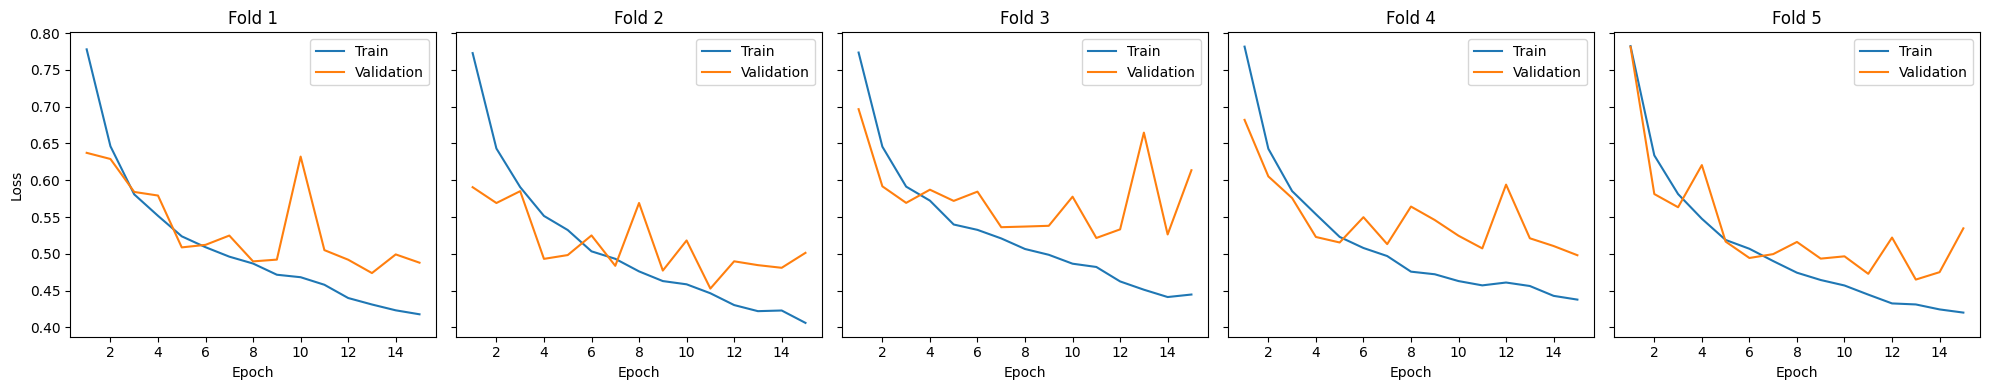

In [ ]:
fig, axes = plt.subplots(1, N_FOLDS, figsize=(4 * N_FOLDS, 4), sharey=True)

for i, ax in enumerate(axes):
    epochs = range(1, len(train_loss_history[i]) + 1)

    ax.plot(epochs, train_loss_history[i], label="Train")
    ax.plot(epochs, val_loss_history[i], label="Validation")

    ax.set_title(f"Fold {i+1}")
    ax.set_xlabel("Epoch")
    if i == 0:
        ax.set_ylabel("Loss")
    ax.legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=120)
plt.show()

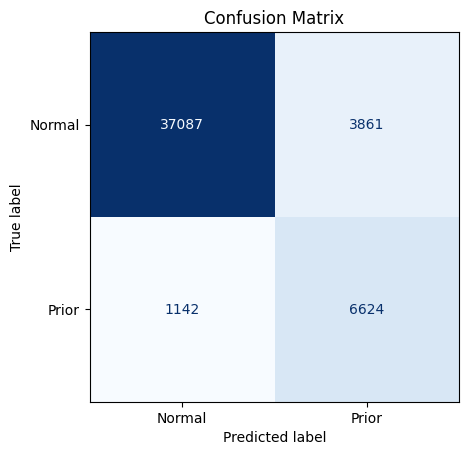

In [ ]:
# Confusion Matrix
all_y_true = np.array(all_y_true)
all_y_pred = np.array(all_y_pred)

cm = confusion_matrix(all_y_true, all_y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Prior"]
)

disp.plot(cmap="Blues", colorbar=False)
plt.title("Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=120)
plt.show()

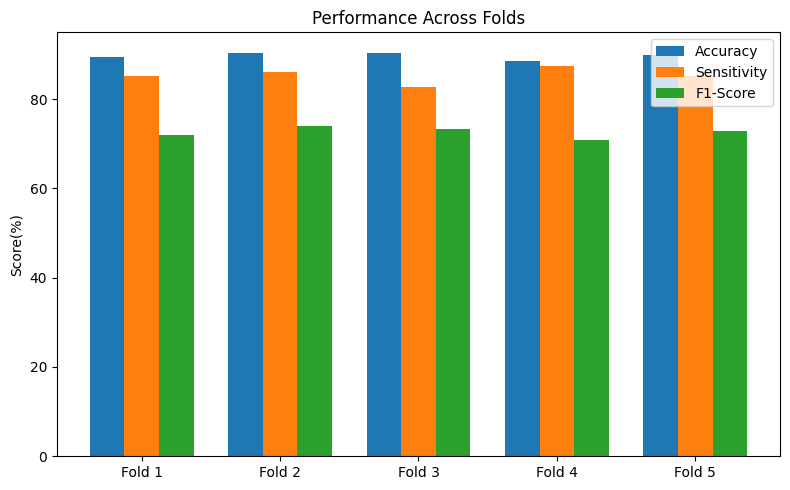

In [ ]:
fold_ids = [f"Fold {r['fold']}" for r in fold_results]
x = np.arange(N_FOLDS)
width = 0.25

plt.figure(figsize=(8, 5))

plt.bar(x - width, [r['accuracy'] * 100 for r in fold_results], width, label="Accuracy")
plt.bar(x, [r['sensitivity'] * 100 for r in fold_results], width, label="Sensitivity")
plt.bar(x + width, [r['f1'] * 100 for r in fold_results], width, label="F1-Score")

plt.xticks(x, fold_ids)
plt.ylabel("Score(%)")
plt.title("Performance Across Folds")
plt.legend()

plt.tight_layout()
plt.savefig("fold_metrics.png", dpi=120)
plt.show()

In [ ]:
# Saving  best-performing fold:

# fold with highest F1 score
best_fold_idx = np.argmax(f1s)
print(f'Best fold by F1: Fold {fold_results[best_fold_idx]["fold"]} '
      f'(F1 = {f1s[best_fold_idx]*100:.2f}%)')

torch.save({
    'model_architecture': 'CNNTransformerModel',
    'model_state_dict'  : best_overall_state,
    'epoch_samples'    : EPOCH_SAMPLES,
    'sampling_rate'  : FS,
    'mean_accuracy'  : np.mean(accs),
    'mean_f1'   : np.mean(f1s),
    'fold_results'  : fold_results,
}, 'cnn_transformer_apnea.pt')


print('Model info saved to cnn_transformer_apnea.pt')

Best fold by F1: Fold 2 (F1 = 73.96%)
Model info saved to cnn_transformer_apnea.pt


In [ ]:
#LOADING THE MODEL:

# from google.colab import drive
# drive.mount('/content/drive')



# checkpoint = torch.load('/content/drive/MyDrive/apnea_ecg_data/cnn_transformer_apnea.pt')


# model = CNNTransformerModel().to(DEVICE)
# model.load_state_dict(checkpoint['model_state_dict'])
# model.eval()
# print('Model loaded')